# Coherence transfer pathway selection with `ctps`

`ctps` is a separate module in this repository (`import ctps`, no dependency on
`spynach`) for the question every phase cycle and gradient scheme answers: which
coherence transfer pathways survive a pulse sequence, with what weight? It ports
CCCP.m (Jerschow & Müller, *J. Magn. Reson.* 134, 17 (1998)) and CCCP++
(Jerschow & Kumar, *J. Magn. Reson.* 160, 59 (2003)), adds the treatment of
non-ideal pulses of Jerschow, *J. Chem. Phys.* 113, 979 (2000), and searches for
cogwheel phase cycles by exact integer arithmetic. The companion notebook is
[`notebooks/ctps.ipynb`](ctps.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/ctps.ipynb)).

*Generated from [`docs/ctps.md`](../ctps.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [The idea, and the conventions](#The-idea,-and-the-conventions)
2. [A stimulated echo with bipolar gradients](#A-stimulated-echo-with-bipolar-gradients)
3. [The pathway explorer](#The-pathway-explorer)
4. [Non-ideal pulses](#Non-ideal-pulses)
5. [Finding a cogwheel cycle](#Finding-a-cogwheel-cycle)
6. [Two nuclei](#Two-nuclei)
7. [Exporting a cycle](#Exporting-a-cycle)
8. [What is checked, and what is pending](#What-is-checked,-and-what-is-pending)

## The idea, and the conventions

A sequence of `n` pulses has `n + 1` periods, numbered from 0 (before the first
pulse) to `n` (detection). Coherence orders change only at pulses. Every
pathway, a list of one order per period, receives a weight that factors into
four parts: the phase cycle (`pc`, the sum over the cycle's steps of
`exp(-i(Δp·φ + φ_rec))` divided by the number of steps), the gradients (`grad`,
attenuation by the dephasing left at detection), diffusion (`diff`) and the
pulses (`pulse`, for non-ideal pulses). The conventions are those of the 1998
paper: `Δp_j = p_j - p_{j-1}`, a pulse phase `φ` multiplies the signal by
`exp(-i Δp φ)`, the receiver by `exp(-i φ_rec)`, and the reported phase `ψ` is
`arg(s)` in degrees as the paper's tables list it. Gyromagnetic ratios are in
rad/s/T, gradient areas in T·s/m, delays in seconds; the sample is a cylinder
with `z_max` half its active length and `x_max` its radius.

In [1]:
import numpy as np

import ctps
from ctps import AllowedOrders, Nucleus, Period, PhaseCycle, Pulse, Sample, Sequence, simulate

print(ctps.__version__)

0.1.0


## A stimulated echo with bipolar gradients

Fig. 4 of the 1998 paper: seven pulses on protons, bipolar gradient pairs around
the two 180° pulses, spoilers along x and y, an 8-step cycle, orders up to ±3,
and only 0 and ±1 allowed after the first pulse. The periods carry their
duration (the delay to the next gradient) and their gradient area; the
`AllowedOrders` grid holds the 0/1 mask per period, a weight other than 1
being an empirical factor (CCCP.m's `allow_paths` entries):

In [2]:
H = Nucleus("1H")  # gamma from the built-in table; Nucleus("X", gamma=...) for anything else
ms = 1e-3
periods = [
    Period(),
    Period.with_gradient(2 * ms, "z", 0.25, 1 * ms),
    Period.with_gradient(2 * ms, "z", -0.25, 1 * ms),
    Period.with_gradient(50 * ms, "x", 0.025, 1 * ms),
    Period.with_gradient(2 * ms, "z", 0.25, 1 * ms),
    Period.with_gradient(2 * ms, "z", -0.25, 1 * ms),
    Period.with_gradient(0.0, "y", 0.025, 1 * ms),
    Period(),
]
allowed = AllowedOrders.standard(3, 8, start=[0], end=[-1]).only(1, [-1, 0, 1])
ste = Sequence(
    nuclei=(H,),
    pulses=tuple(Pulse("1H", label=f"{'180' if j in (1, 4) else '90'}") for j in range(7)),
    periods=tuple(periods),
    allowed={"1H": allowed},
    sample=Sample(z_max=5 * ms, x_max=2.5 * ms),  # 10 mm long, 5 mm across
    diffusion=7e-10,
)
cycle = PhaseCycle.explicit(
    phases=[[0, 0, 1, 1, 2, 2, 3, 3], [1, 2, 2, 3, 3, 0, 0, 1], [0], [2, 2, 3, 3], [3, 3, 0, 0], [2], [0]],
    receiver=[0, 2, 0, 2, 2, 0, 2, 0],
    base=4,
)
wanted = [(0, -1, 1, 0, 1, -1, 0, -1), (0, 1, -1, 0, -1, 1, 0, -1)]
result = simulate(ste, cycle, wanted=wanted)
print(f"{result.n_enumerated} pathways enumerated, {len(result)} above threshold")
for row in result.table()[:4]:
    print(row["pathway"], f"total {row['total']:.4f}  pc {row['pc']:.4f}  grad {row['grad']:.4f}  diff {row['diff']:.4f}")

50421 pathways enumerated, 10662 above threshold
[0, 0, -1, 0, 0, 1, 0, -1] total 0.5971  pc 0.7071  grad 1.0000  diff 0.8444
[0, 0, 1, 0, 0, -1, 0, -1] total 0.5971  pc 0.7071  grad 1.0000  diff 0.8444
[0, -1, -3, 0, -3, -1, 0, -1] total 0.5149  pc 1.0000  grad 1.0000  diff 0.5149
[0, 1, 3, 0, 3, 1, 0, -1] total 0.5149  pc 1.0000  grad 1.0000  diff 0.5149


The two wanted pathways carry `pc = 1`, `grad = 1` and `diff = 0.515`, the
values of the paper's table; the pathways that leak through the spoilers have
`grad = 0.0233`, the far-field value of the transverse attenuation. The
`pulse` column of the paper comes from CCCP.m's empirical model of the two
180° pulses, which the next section replaces with the treatment of the 2000
paper. In a notebook the result displays as a table, with the wanted pathways
in bold and a count of the unwanted ones above 1% of the strongest wanted:

In [3]:
result.top(6)

#,pathway,total,ψ / °,pc,grad,diff,pulse
1,"0,0,-1,0,0,+1,0,-1",0.5971,315,0.7071,1,0.8444,1
2,"0,0,+1,0,0,-1,0,-1",0.5971,45,0.7071,1,0.8444,1
3,"0,-1,-3,0,-3,-1,0,-1",0.5149,0,1,1,0.5149,1
4,"0,+1,+3,0,+3,+1,0,-1",0.5149,0,1,1,0.5149,1
5,"0,-1,+1,0,+1,-1,0,-1",0.5149,0,1,1,0.5149,1
6,"0,+1,-1,0,-1,+1,0,-1",0.5149,0,1,1,0.5149,1


## The pathway explorer

`plot_pathways` draws the sequence above the coherence orders, every pathway as
a step line whose width follows its weight, wanted pathways solid and the rest
dashed. The slider steps through the ranked pathways, dimming the others and
listing the selected one's factors; hovering a segment shows them too, and the
legend toggles single pathways. Periods are drawn with equal width
(`to_scale=True` uses the real delays):

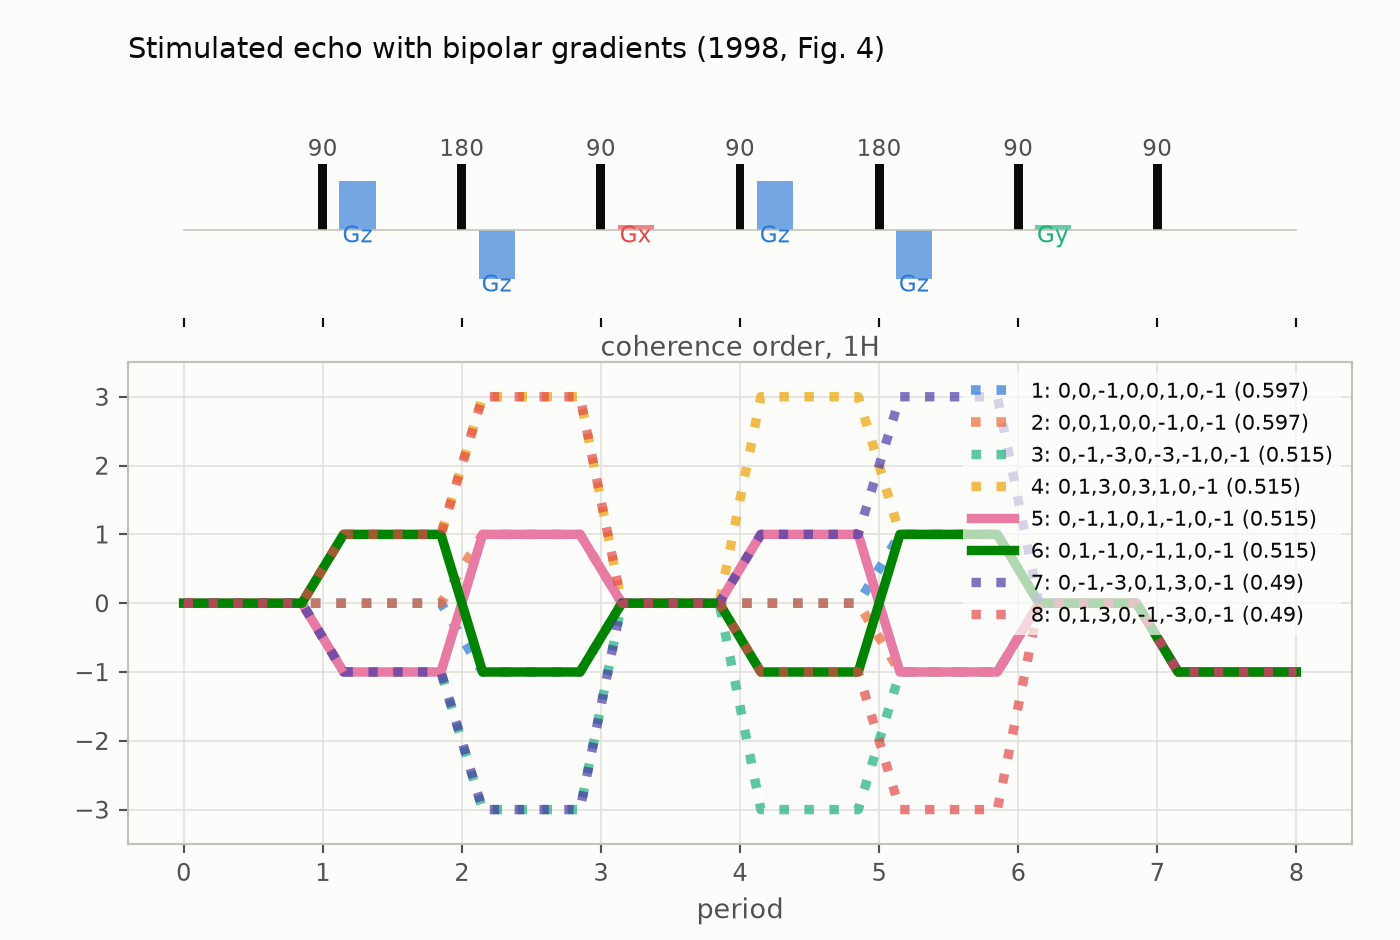

In [4]:
from ctps.plot import plot_pathways

plot_pathways(result, top=8, title="Stimulated echo with bipolar gradients (1998, Fig. 4)")

Indexing the result gives one pathway with its factors, also as a bar chart in
the notebook:

In [5]:
print(result[2])
print(result[2].factors)

Pathway(0,-1,-3,0,-3,-1,0,-1: total=0.5149, pc=1, grad=1, diff=0.5149, pulse=1)
{'pc': 1.0, 'grad': 1.0, 'diff': 0.514893950868514, 'pulse': 1.0}


## Non-ideal pulses

Each pulse is of one of three kinds, beyond `"free"` (its order change governed
by the allowed orders alone, as for the 90° pulses above): `"perfect_180"`
inverts the order exactly; `"imperfect_180"` deviates from π by `beta` with the
rotation axis tilted by `epsilon` (`tan ε = Δω/ω₁`); `"small_flip"` is a pulse
of flip angle `beta`. The last two weight every transfer `p -> p'` by the
leading term of the rotation matrix element from *J. Chem. Phys.* 113, 979
(2000): near π the inverted order passes with weight 1, the non-inverted one with
`f |u|^(2|p|)` and `|u|² = (β/2)² + ε²`, and `p -> 0` leaks at first order; for a
small flip angle the weight is `f (β/2)^|p - p'|`. The coefficients `f` depend on
the rank, which defaults to `2j` of the nucleus (the paper's upper bound), and on
`Nucleus(n_spins=...)` for coupled spins of one species (the paper's Table III).
Every formula and table of that paper was recomputed before use; three typos
are recorded in `ctps.engine.pulse`. `exact_pulses=True` in `simulate` uses the
full rotation matrices instead of the leading terms.

In [6]:
imperfect = Sequence(
    nuclei=ste.nuclei,
    pulses=tuple(
        Pulse("1H", "imperfect_180", beta=0.1, epsilon=0.05, label="180") if j in (1, 4) else Pulse("1H", label="90")
        for j in range(7)
    ),
    periods=ste.periods,
    allowed={"1H": allowed},
    sample=ste.sample,
    diffusion=ste.diffusion,
)
result_imperfect = simulate(imperfect, cycle, wanted=wanted)
for row in result_imperfect.table()[:5]:
    print(row["pathway"], f"total {row['total']:.4g}  pulse {row['pulse']:.4g}")
print(f"{result_imperfect.leakage(0.01)} unwanted pathways above 1% of the wanted ones")

[0, -1, 1, 0, 1, -1, 0, -1] total 0.5149  pulse 1
[0, 1, -1, 0, -1, 1, 0, -1] total 0.5149  pulse 1
[0, -1, 1, 0, 1, -1, -1, -1] total 0.01202  pulse 1
[0, -1, 1, 0, 1, -1, 1, -1] total 0.01202  pulse 1
[0, 1, -1, 0, -1, 1, -1, -1] total 0.01202  pulse 1
10 unwanted pathways above 1% of the wanted ones


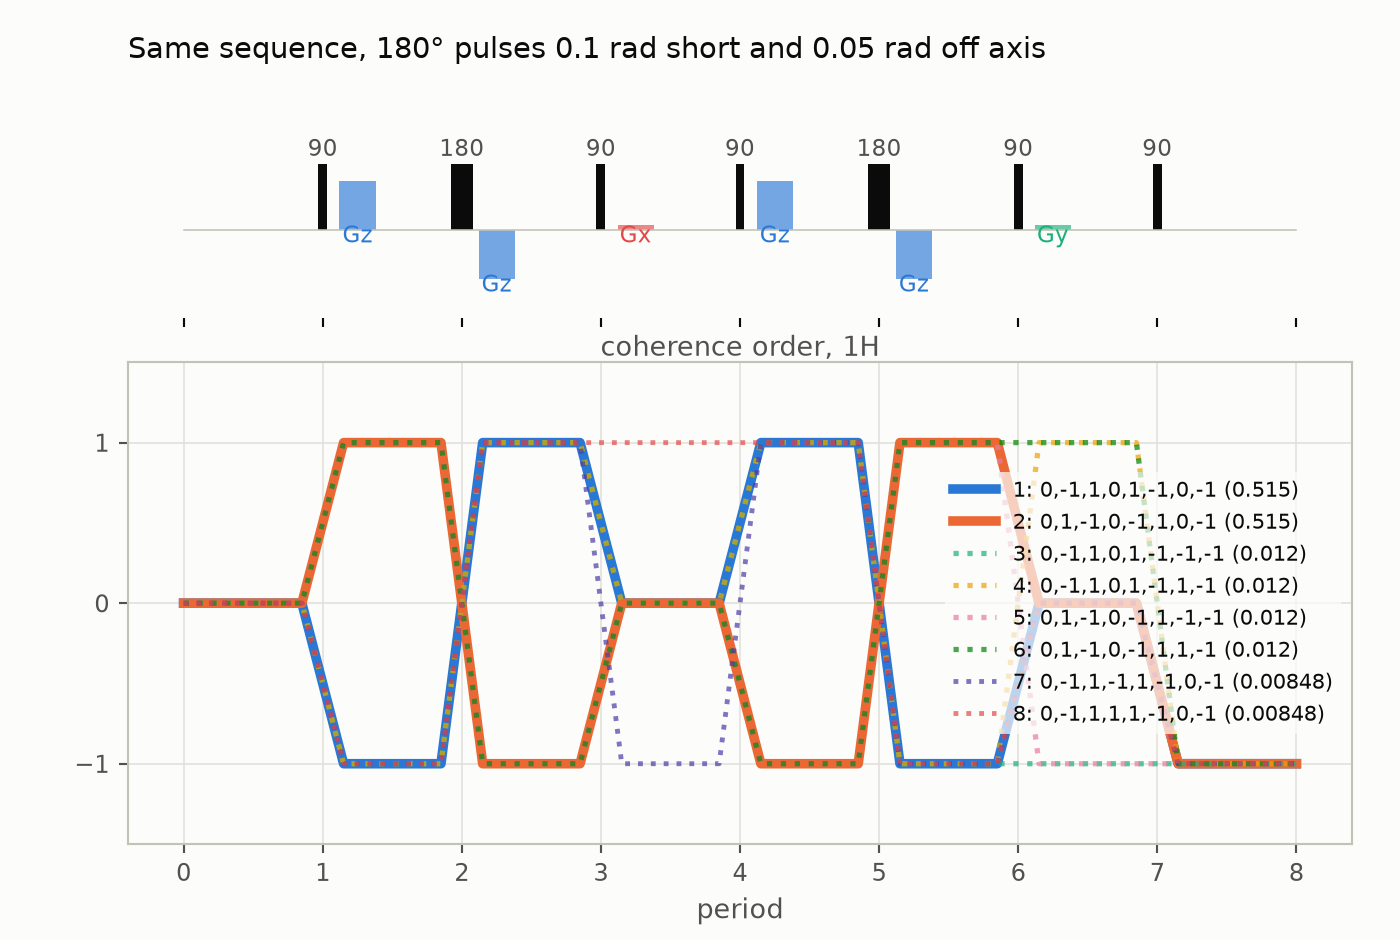

In [7]:
plot_pathways(result_imperfect, top=8, title="Same sequence, 180° pulses 0.1 rad short and 0.05 rad off axis")

## Finding a cogwheel cycle

A cogwheel cycle `COG_N(ν_1..ν_n; ν_rec)` gives pulse `i` the phase
`2π ν_i m / N` at step `m`; a pathway survives it iff
`Σ ν_j Δp_j + ν_rec ≡ 0 (mod N)`. `find_cycle` scans `N` upwards and tests all
winding-number candidates at once as one integer matrix product over the set of
jump differences to the wanted pathway, after the reductions of the literature
(one winding number fixed, one representative per unit multiple, pulses with no
jump difference left out). The Hughes–Carravetta–Levitt construction
(`hcl_cycle`) gives a cycle immediately and bounds the scan. Triple-quantum
MAS on a spin 3/2, wanted pathway `0, +3, +1, -1`:

In [8]:
from ctps import find_cycle, hcl_cycle

mqmas = Sequence.simple(n_pulses=3, p_max=3)  # one nucleus, orders up to 3, start at 0, detect -1
print("HCL construction:", hcl_cycle([3, 1], [3, 3]).cog_string())
found = find_cycle(mqmas, [(0, 3, 1, -1)])
print("smallest cycle:", found.best.cog_string(), "after scanning N =", found.scanned[0], "..", found.scanned[-1])
every = find_cycle(mqmas, [(0, 3, 1, -1)], N_min=23, N_max=23, all_solutions=True)
print(len(every.solutions), "representative(s) at N = 23: the 22 cycles of Levitt 2002 are one orbit under unit multiples")

HCL construction: COG23(0,3,4;14)
smallest cycle: COG23(0,1,9;20) after scanning N = 2 .. 23
1 representative(s) at N = 23: the 22 cycles of Levitt 2002 are one orbit under unit multiples


The selection diagram of Levitt, Madhu and Hughes shows why: the running phase
index `Σ ν Δp` of every pathway branches at each pulse, and only pathways that
end on a hole of the barrier (every `N`) pass. The phase-vector plot shows the
`N` phasors of one pathway adding up to its `pc` factor:

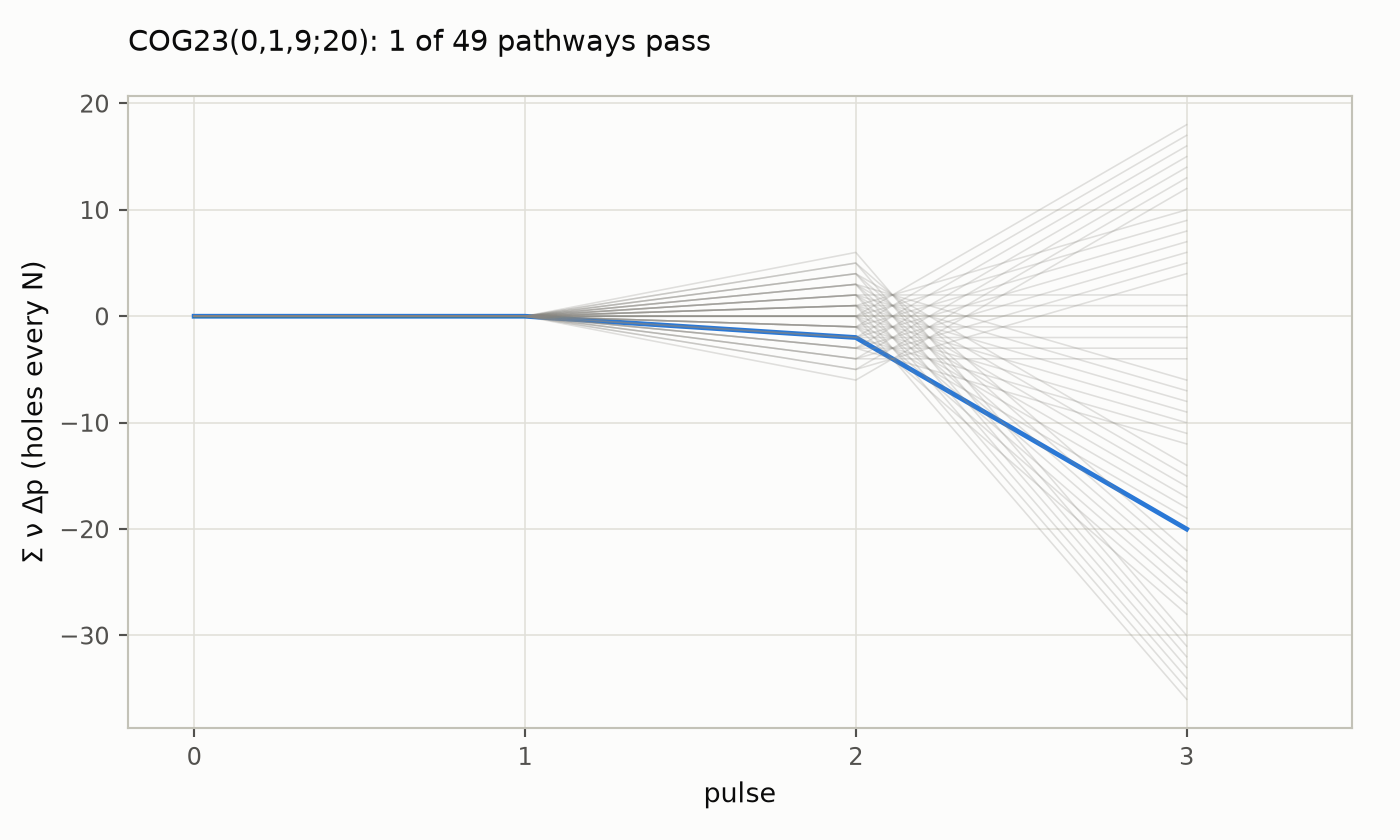

In [9]:
from ctps.plot import plot_phase_vectors, plot_selection_diagram

plot_selection_diagram(found.best, mqmas, wanted=[(0, 3, 1, -1)])

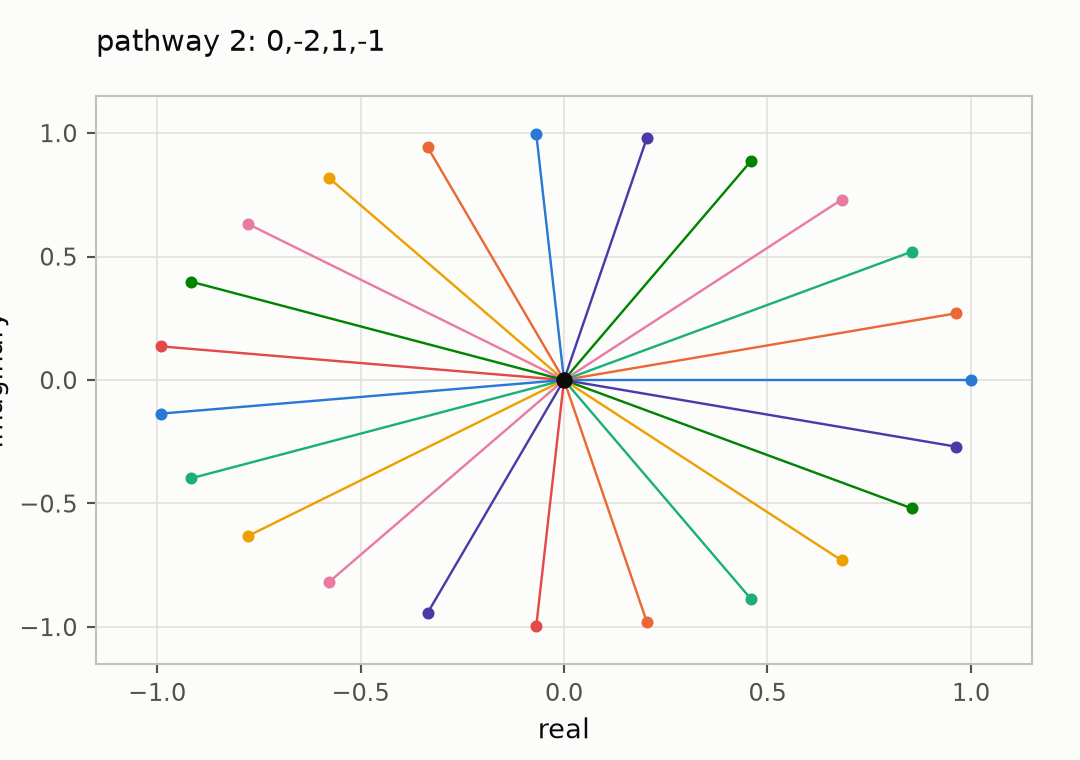

In [10]:
mq_result = simulate(mqmas, found.best.cycle, wanted=[(0, 3, 1, -1)], epsilon=0, cutoff=0)  # keep rejected pathways
plot_phase_vectors(mq_result, 1)

Gradients can be optimised too. `crusher_scheme` maximises the dephasing of
the worst and the average unwanted pathway, the geometry-free objective of
DOTCOPS (Landheer & Juchem, *MRM* 81, 2209 (2019)), subject to refocusing the
wanted pathway and to per-crusher bounds; STEAM with the middle crusher allowed
twice the area reaches the paper's `min D = √3`:

In [11]:
from ctps.optimize import crusher_scheme

steam = Sequence.simple(n_pulses=3, p_max=1)
bounds = np.array([[0, 0, 0], [1, 1, 1], [2, 2, 2], [1, 1, 1]], dtype=float)  # per period and axis
scheme = crusher_scheme(steam, [(0, 1, 0, -1)], bounds=bounds, starts=40)
print(f"min D = {scheme['min_D']:.3f} (sqrt 3 = {np.sqrt(3):.3f}), mean D = {scheme['mean_D']:.3f}")

min D = 1.732 (sqrt 3 = 1.732), mean D = 3.682


With a fixed number of steps, `coverage` returns the cycle cancelling the most
unwanted pathways, the mode of Landheer & Juchem (MRM 83, 391 (2020)); sLASER
with one spin has 80 unwanted pathways, and 8 steps cancel all but one:

In [12]:
from ctps import coverage

slaser = Sequence.simple(n_pulses=5, p_max=1)
for N in (8, 16):
    best = coverage(slaser, [(0, -1, 1, -1, 1, -1)], N).best
    print(best.cog_string(), f"{best.survivors} unwanted pathways survive")

COG8(0,1,0,1,0;4) 1 unwanted pathways survive
COG16(0,1,0,1,0;12) 0 unwanted pathways survive


## Two nuclei

Pulses act on one nucleus each; the other nuclei carry their orders forward,
and the total order is the sum. The nine-pulse HSQC of the 1998 paper (Fig. 9)
on a 1H-13C pair, with perfect 180° pulses and the usual four-step cycle on the
two carbon 90° pulses; the wanted pathways carry proton coherence through the
first INEPT, carbon ±1 during the evolution, and proton −1 at detection:

27 pathways; 18 with a nonzero phase-cycle factor


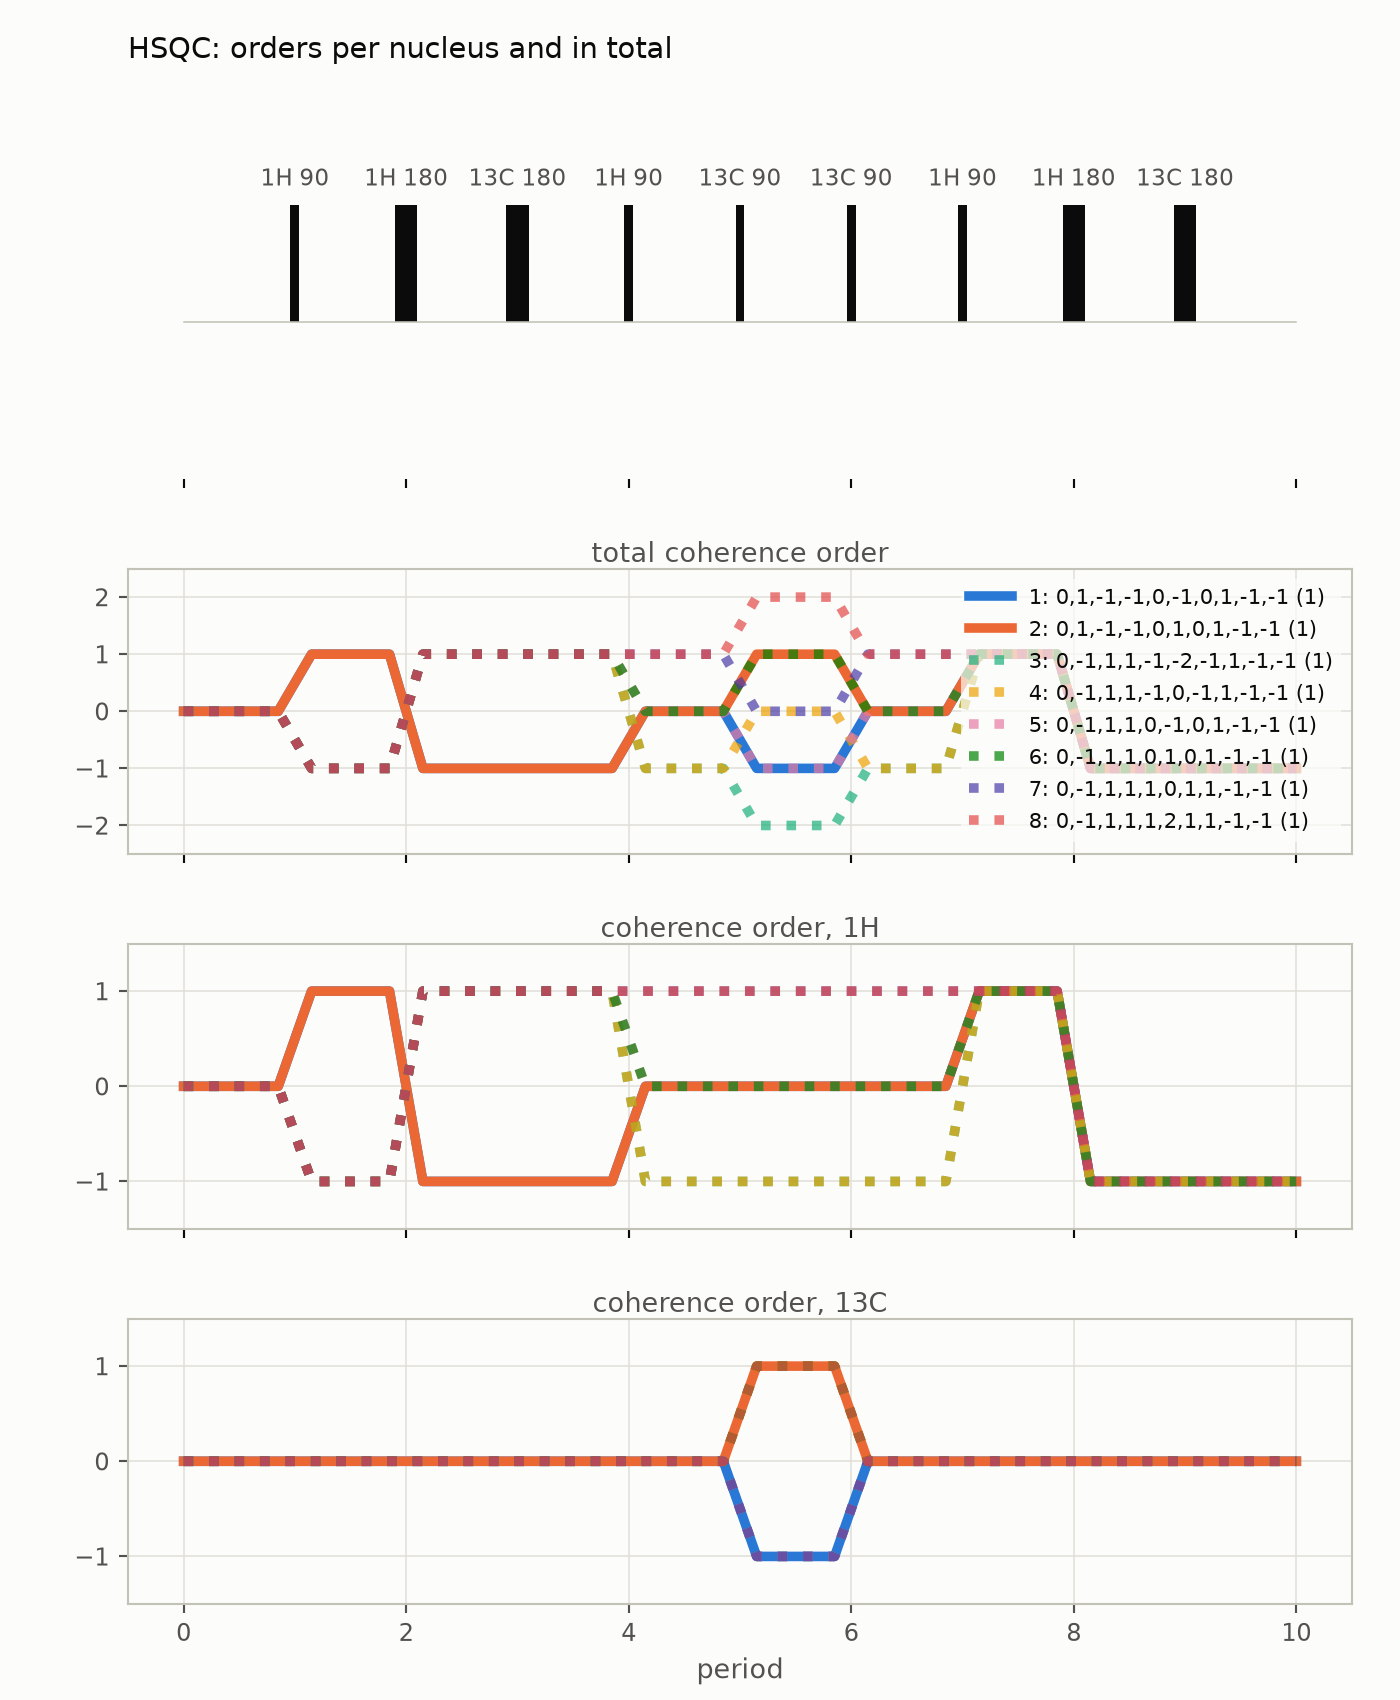

In [13]:
C = Nucleus("13C")
kinds = ["90", "180", "180", "90", "90", "90", "90", "180", "180"]
nuclei = ["1H", "1H", "13C", "1H", "13C", "13C", "1H", "1H", "13C"]
pulses = tuple(
    Pulse(n, "perfect_180" if k == "180" else "free", label=f"{n} {k}") for n, k in zip(nuclei, kinds)
)
hsqc = Sequence(
    nuclei=(H, C),
    pulses=pulses,
    periods=tuple(Period() for _ in range(10)),
    allowed={"1H": AllowedOrders.standard(1, 10), "13C": AllowedOrders.standard(1, 10, end=[0])},
)
hsqc_cycle = PhaseCycle.explicit([[0]] * 4 + [[0, 2], [0, 0, 2, 2], [0], [0], [0]], [0, 2, 2, 0], base=4)
hsqc_wanted = [(0, 1, -1, -1, 0, 1, 0, 1, -1, -1), (0, 1, -1, -1, 0, -1, 0, 1, -1, -1)]
hsqc_result = simulate(hsqc, hsqc_cycle, wanted=hsqc_wanted, epsilon=0)
print(hsqc_result.n_enumerated, "pathways;", len(hsqc_result), "with a nonzero phase-cycle factor")
plot_pathways(hsqc_result, top=8, title="HSQC: orders per nucleus and in total")

## Exporting a cycle

`ctps.io` prints a cycle in Bruker pulse-program syntax (receiver `ph31`), as a
phase table in degrees for any console, parses `COG` strings, and writes results
as CSV or JSON (`write_csv`, `write_json`):

In [14]:
from ctps.io import bruker_phase_program, parse_cog, phase_table

print(bruker_phase_program(found.best.cycle))
print(phase_table(parse_cog("COG11(0,1,0,1,0,1;6)"))[:2])

ph1=(23) 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
ph2=(23) 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22
ph3=(23) 0 9 18 4 13 22 8 17 3 12 21 7 16 2 11 20 6 15 1 10 19 5 14
ph31=(23) 0 20 17 14 11 8 5 2 22 19 16 13 10 7 4 1 21 18 15 12 9 6 3

[{'step': 0, 'pulse_1': 0.0, 'pulse_2': 0.0, 'pulse_3': 0.0, 'pulse_4': 0.0, 'pulse_5': 0.0, 'pulse_6': 0.0, 'receiver': 0.0}, {'step': 1, 'pulse_1': 0.0, 'pulse_2': 32.727273, 'pulse_3': 0.0, 'pulse_4': 32.727273, 'pulse_5': 0.0, 'pulse_6': 32.727273, 'receiver': 196.363636}]


## What is checked, and what is pending

The tests in `tests/ctps/` reproduce the 1998 Fig. 4 table (pathway count,
phase-cycle, gradient and diffusion factors), every explicit cogwheel cycle of
the 2002, 2003 and 2004 papers (each selects exactly its stated pathways), the
smallest-`N` claims of Levitt 2002 and the `N_opt` table of Hughes 2004, the
coverage fractions of Landheer 2020 for sLASER, and the tables of the 2000 pulse
paper against exact rotation matrices. Two items wait for the original sources
(`/cccp`, `/cccp-pp`): the delay after the last gradient that CCCP.m uses in the
diffusion integral, and CCCP.m's empirical 180° model (`Pulse(kind="cccp_1998")`
is a provisional reading), together with the loaders for CCCP.m scripts and
CCCP++ `.par` files and the parity fixtures from the programs. The 2003 PFG
cogwheel `COG80(0,58,18,0,3,1;13)` does not select its stated pathways as printed
and is kept as a skipped fixture.

| CCCP.m variable or `.par` key | here |
|---|---|
| `gamma`, `spin_system` | `Nucleus(name, gamma, spin, n_spins)` |
| `allow_paths` (one 0/1 matrix per nucleus) | `AllowedOrders` per nucleus, weights other than 1 as empirical factors |
| `ph`, `base`, `phrec`, `recbase` | `PhaseCycle.explicit(phases, receiver, base)`, `receiver_base` |
| `COGN`, `COGwdg` | `PhaseCycle.cogwheel(N, nu, nu_rec)`, `find_cycle` |
| `pulses` (flip angles) | `Pulse(kind, beta, epsilon)` |
| `grads`, `sampledim`, `intergrad_dels`, `diffconst` | `Period(duration, gradient)`, `Sample`, `Sequence(diffusion=...)` |
| `cutoff`, `epsilon` | `simulate(epsilon=..., cutoff=...)` |
| `which_nucl` | `Pulse.nucleus` |

[Coherence transfer pathways: worked examples](ctps-examples.ipynb) continues
with ten worked cases and the checks behind the tests as runnable examples.

Not ported, on purpose: the density-matrix pulse-damping tier of CCCP.m
(AX/AMX/AMXinv), which will come through Spynach; a command line and a GUI; GPU
backends (hot loops are marked `# GPU:`). The module can be removed without
touching Spynach (`src/ctps/README.md` gives the recipe).